# A steady-state solver for driven TDDFT: borrowing the Kaspar–Thoss idea
### Electrons in a continuous-wave field, solved as coupled matrix equations with a Sylvester preconditioner

Kaspar & Thoss (J. Phys. Chem. A 2021, 125, 5190) solve the **steady state** of the hierarchical equations of motion (HEOM) without ever building the big matrix: the hierarchy is written as *coupled matrix equations*, every operation is a small matrix product, and a Krylov method (CGNE) with a preconditioner that is diagonal in the eigenbasis does the work.

**This notebook transplants that idea to time-dependent density-functional theory (TDDFT).** An atom or molecule in a monochromatic field $E_0\cos\omega t$ with some damping $\gamma$ settles into a periodic **steady state** (a Floquet state). Write the density-matrix change as
$$
\Delta(t)=\Delta_0+\sum_{n\ge1}\big(\Delta_n e^{-in\omega t}+\text{h.c.}\big).
$$
Then the harmonics $\Delta_n$ play the role of the auxiliary density operators, and:

| HEOM steady state (paper) | Driven TDDFT steady state (this notebook) |
|---|---|
| ADO $\tilde\rho^{(n)}_{j_n\dots j_1}$, tier $n$ | Floquet harmonic $\Delta_n$ (a $M\times M$ matrix in the Kohn–Sham basis) |
| $-i[\tilde H_S,\cdot]-\sum\gamma_j$ (diagonal in the eigenbasis) | $n\omega+i\gamma-(\varepsilon_p-\varepsilon_q)$ (diagonal in the KS eigenbasis) |
| Sylvester preconditioner = element-wise division | **the same**: element-wise division by $n\omega+i\gamma-(\varepsilon_p-\varepsilon_q)$ |
| tier-up / tier-down coupling via $\tilde{ A},\tilde{ C}$ | harmonic coupling via the field and the commutators $[\Delta F_m+V_m,\Delta_{n-m}]$ |
| hierarchy depth $N_T$ | harmonic cutoff $H$ |
| coupled matrix equation, CGNE with matrix-free adjoint | **the same**, for the occupied–virtual block with the Hartree–xc kernel |
| reference: real-time propagation (RTP), direct LU | reference: real-time propagation of the damped TDKS equations, dense solve |

**What is different.** The coupling *inside* one tier is the Hartree–exchange–correlation kernel, and the steady state is nonlinear in the field, so harmonics are coupled by a nonlinear fixed-point problem that we solve with Newton–Krylov, using the linear tier solver as the inner engine. There is no singular normalization row: the damping $\gamma>0$ makes every tier operator nonsingular.

**The model (so that everything is testable and self-contained).** No electronic-structure package is available in a bare Colab session, so we use a **1D soft-Coulomb molecule** on a grid: $w(x)=1/\sqrt{x^2+1}$ for all interactions, spin-restricted Kohn–Sham, and the **adiabatic LDA exchange** of the 1D soft-Coulomb uniform gas, whose derivatives are analytic (Bessel functions). There is no correlation functional. This is a *model* TDDFT, not a quantum-chemistry result for a real molecule. All comparisons are inside the same finite Kohn–Sham basis, so the numbers test the *solver*, not the functional.

## 1. Imports and the functional
For the 1D uniform gas with interaction $w(x)=1/\sqrt{x^2+1}$, the exchange energy per length is $F(n)=-\frac{2}{\pi^2}\int_0^\infty w(x)\frac{\sin^2(k_Fx)}{x^2}dx$ with $k_F=\pi n/2$. Differentiating under the integral gives closed forms, with $K_0$ the modified Bessel function:
$$
v_x(n)=-\frac1\pi\int_0^{\pi n}K_0(t)\,dt,\qquad f_x(n)=\frac{dv_x}{dn}=-K_0(\pi n).
$$
The first cell checks them against brute-force quadrature.

In [1]:
import time, warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import k0, iti0k0
from scipy.integrate import quad
np.set_printoptions(precision=6, suppress=True)
warnings.filterwarnings("ignore")

In [2]:
# ---------------------------------------------------------------------------
# 1D soft-Coulomb LDA exchange (analytic):  v_x(n) = -(1/pi) int_0^{pi n} K0,  f_x(n) = -K0(pi n)
# ---------------------------------------------------------------------------
def vx_lda(n):  return -iti0k0(np.pi*np.maximum(n, 0.0))[1]/np.pi
def fx_lda(n):  return -k0(np.pi*np.maximum(n, 1e-12))

In [3]:
# --- test: analytic v_x, f_x against numerical quadrature of the exchange energy of the uniform gas
w_sc = lambda x: 1/np.sqrt(x*x + 1)
def F_num(n):
    k = np.pi*n/2
    val = quad(lambda x: w_sc(x)*np.sin(k*x)**2/x**2, 0, 2000, limit=4000)[0] + 0.25/2000**2   # analytic tail
    return -(2/np.pi**2)*val
print("   n      v_x analytic   dF/dn numeric     f_x analytic   d2F/dn2 numeric")
for n in (0.05, 0.2, 0.5, 1.0):
    h = 1e-4
    print(f"{n:5.2f}   {float(vx_lda(n)):12.6f}   {(F_num(n+h)-F_num(n-h))/(2*h):12.6f}   {float(fx_lda(n)):12.6f}   {(F_num(n+1e-3)-2*F_num(n)+F_num(n-1e-3))/1e-6:12.6f}")

   n      v_x analytic   dF/dn numeric     f_x analytic   d2F/dn2 numeric
 0.05      -0.148686      -0.148686      -1.985268      -1.985302
 0.20      -0.328945      -0.328945      -0.741774      -0.741824
 0.50      -0.448514      -0.448513      -0.195129      -0.195129
 1.00      -0.491625      -0.491625      -0.029509      -0.029461


## 2. The molecule and its Kohn–Sham basis
`Molecule` puts nuclei of charge $Z_A$ at positions $R_A$ on a real-space grid, solves the spin-restricted Kohn–Sham equations self-consistently, and keeps the lowest $M$ Kohn–Sham orbitals as the working basis. In that basis the unknowns are $M\times M$ matrices — the analogue of the ADOs. We use an asymmetric diatomic ($Z=3$ and $Z=1$, four electrons, so two occupied orbitals); the asymmetry allows even harmonics and a rectified (dc) dipole.

In [4]:
# ---------------------------------------------------------------------------
# Molecule on a real-space grid, spin-restricted Kohn-Sham with ALDA exchange
# ---------------------------------------------------------------------------
class Molecule:
    def __init__(self, charges, positions, L=16.0, dx=0.2, M=60):
        self.Z = np.array(charges, float); self.R = np.array(positions, float)
        Ne = int(round(self.Z.sum())); assert Ne % 2 == 0
        self.no = Ne//2
        self.x = np.arange(-L, L + dx/2, dx); self.dx = dx; Ng = len(self.x); self.Ng = Ng
        w = 1/np.sqrt((self.x[:, None]-self.x[None, :])**2 + 1)
        self.W = w*dx                                              # Hartree kernel matrix (includes dx)
        self.vext = -sum(Z/np.sqrt((self.x-R)**2 + 1) for Z, R in zip(self.Z, self.R))
        T = (np.diag(np.full(Ng, 1/dx**2)) - np.diag(np.full(Ng-1, 0.5/dx**2), 1) - np.diag(np.full(Ng-1, 0.5/dx**2), -1))
        n = np.zeros(Ng)
        # SCF with linear mixing
        for it in range(500):
            v = self.vext + self.W @ n + vx_lda(n)
            e, C = np.linalg.eigh(T + np.diag(v))
            nnew = 2*np.sum(C[:, :self.no]**2, axis=1)/dx
            err = np.abs(nnew - n).max()
            n = 0.5*n + 0.5*nnew if it else nnew
            if err < 1e-11: break
        self.scf_iters = it
        v = self.vext + self.W @ n + vx_lda(n)
        e, C = np.linalg.eigh(T + np.diag(v))
        self.n0 = 2*np.sum(C[:, :self.no]**2, axis=1)/dx
        self.eps, self.C = e[:M], C[:, :M]; self.M = M
        self.f = np.zeros(M); self.f[:self.no] = 1.0                # occupation per spin
        self.fx0 = fx_lda(self.n0)
        self.xop = self.C.T @ (self.x[:, None]*self.C)               # dipole matrix in the KS basis
        self.nv = M - self.no
        self.Co, self.Cv = self.C[:, :self.no], self.C[:, self.no:]

    # density (on grid) from a matrix Delta in the KS basis
    def dens(self, D):  return (2/self.dx)*np.sum((self.C @ D)*self.C, axis=1)
    def pot_to_mat(self, v):  return self.C.T @ (v[:, None]*self.C)
    # linearised Hxc kernel acting on a matrix Delta (adiabatic)
    def Kmap(self, D):
        dn = self.dens(D)
        return self.pot_to_mat(self.W @ dn + self.fx0*dn)

## 3. One tier: a coupled matrix equation with a Sylvester preconditioner
For harmonic frequency $\Omega=n\omega$ the linearised steady-state equation in the KS eigenbasis is
$$
\big(\Omega+i\gamma-(\varepsilon_p-\varepsilon_q)\big)\Delta_{pq}-(f_q-f_p)\,\big[K(\Delta)\big]_{pq}=S_{pq},
$$
where $ K$ applies the adiabatic Hartree–xc kernel ($\delta v=(w+f_x)\,\delta n$) and returns its KS matrix elements, and $S$ collects the driving field and the nonlinear terms of the other harmonics. Because $f_q-f_p$ vanishes for occupied–occupied and virtual–virtual pairs, those blocks are solved exactly by **element-wise division** (the Sylvester solve of the paper); only the occupied–virtual block $(X,Y)=(\Delta_{ai},\Delta_{ia})$ needs the iterative solver:
$$
 A(X,Y)=\big(D^+X- K(X+Y),\ D^-Y+ K(X+Y)\big),\qquad D^\pm_{ai}=\Omega+i\gamma\mp(\varepsilon_a-\varepsilon_i).
$$
The kernel is self-adjoint, so the adjoint is available matrix-free: $ A^\dagger(P,Q)=(\bar D^+P+ K(Q-P),\ \bar D^-Q+ K(Q-P))$. Operations cost $ O(N_g\,n_v\,n_o)$; the explicit matrix would be $(2n_vn_o)^2$.

`Tier.solve_cgne` is CGNE with optional left preconditioning by $1/D^\pm$; `Tier.solve_dense` builds the explicit matrix as a reference.

In [5]:
# ---------------------------------------------------------------------------
# One tier (one Floquet harmonic):  solve  A(Delta) = S   with
#   A(Delta)_pq = (Omega + i gamma - (eps_p-eps_q)) Delta_pq - (f_q - f_p) Kmap(Delta)_pq .
# oo and vv blocks decouple from the kernel -> element-wise division (exactly the Sylvester solve);
# the ov / vo blocks (X,Y) form the coupled matrix equation solved here.
# ---------------------------------------------------------------------------
class Tier:
    def __init__(self, mol, Omega, gamma):
        self.m = mol; no = mol.no
        de = mol.eps[:, None] - mol.eps[None, :]
        self.D = Omega + 1j*gamma - de                                   # full M x M
        self.Dp = self.D[no:, :no]                                       # (a,i) : Delta_ai
        self.Dm = self.D[:no, no:].T                                     # (a,i) : Delta_ia stored as [a,i]
        self.Pinp, self.Pinm = 1/self.Dp, 1/self.Dm
        self.Cv, self.Co, self.dx = mol.Cv, mol.Co, mol.dx
        self.nmv = 0; self.lam = 1.0                                     # lam scales the Hxc kernel (0 = independent KS particles)
    def K(self, U):                                                      # kernel on ov density  U = X + Y  (nv x no)
        self.nmv += 1
        m = self.m
        dn = (2/self.dx)*np.sum((self.Cv @ U)*self.Co, axis=1)
        return self.lam*(self.Cv.T @ ((m.W @ dn + m.fx0*dn)[:, None]*self.Co))
    def A(self, Z):
        X, Y = Z; k = self.K(X + Y)
        return (self.Dp*X - k, self.Dm*Y + k)
    def Aadj(self, Z):
        P, Q = Z; k = self.K(Q - P)
        return (self.Dp.conj()*P + k, self.Dm.conj()*Q + k)
    def dense_matrix(self):
        m = self.m; nv, no = m.nv, m.no; n = nv*no
        # pair densities  rho_ai(x) = (2/dx) Cv[x,a] Co[x,i]
        Pm = (2/self.dx)*(self.Cv[:, :, None]*self.Co[:, None, :]).reshape(m.Ng, n)
        Kd = self.lam*(((self.Cv[:, :, None]*self.Co[:, None, :]).reshape(m.Ng, n)).T @ ((m.W + np.diag(m.fx0)) @ Pm))
        A = np.zeros((2*n, 2*n), complex)
        A[:n, :n] = np.diag(self.Dp.ravel()) - Kd; A[:n, n:] = -Kd
        A[n:, :n] = Kd;                       A[n:, n:] = np.diag(self.Dm.ravel()) + Kd
        return A
    # ---- solvers for the ov/vo block ----
    def solve_dense(self, Sp, Sm):
        n = Sp.size; A = self.dense_matrix()
        z = np.linalg.solve(A, np.concatenate([Sp.ravel(), Sm.ravel()]))
        sh = Sp.shape
        return z[:n].reshape(sh), z[n:].reshape(sh), 0
    def solve_cgne(self, Sp, Sm, tol=1e-10, maxit=5000, precond=True):
        b = (Sp, Sm)
        if precond:
            def M(Z):
                a = self.A(Z); return (self.Pinp*a[0], self.Pinm*a[1])
            Mt = lambda R: self.Aadj((self.Pinp.conj()*R[0], self.Pinm.conj()*R[1]))
            b = (self.Pinp*Sp, self.Pinm*Sm)
        else:
            M, Mt = self.A, self.Aadj
        nrm = lambda Z: np.sqrt(np.vdot(Z[0], Z[0]).real + np.vdot(Z[1], Z[1]).real)
        dot = lambda P, Q: np.vdot(P[0], Q[0]).real + np.vdot(P[1], Q[1]).real
        bn = nrm(b)
        Y = (np.zeros_like(Sp), np.zeros_like(Sm)); r = b; p = Mt(r); rr = dot(r, r); it = 0
        while np.sqrt(rr) > tol*max(bn, 1e-300) and it < maxit:
            q = M(p); al = rr/dot(p, p)
            Y = (Y[0] + al*p[0], Y[1] + al*p[1]); r = (r[0] - al*q[0], r[1] - al*q[1])
            rn = dot(r, r); be = rn/rr; rr = rn
            pn = Mt(r); p = (pn[0] + be*p[0], pn[1] + be*p[1]); it += 1
        return Y[0], Y[1], it
    # ---- full tier: source S (M x M) -> Delta (M x M) ----
    def solve(self, S, method='cgne', **kw):
        m = self.m; no = m.no
        D = np.zeros_like(S)
        D[:no, :no] = S[:no, :no]/self.D[:no, :no]; D[no:, no:] = S[no:, no:]/self.D[no:, no:]
        # density generated by the (kernel-free) oo/vv blocks feeds the ov/vo equations
        dn = m.dens(D); kk = m.pot_to_mat(m.W @ dn + m.fx0*dn)
        Sp = S[no:, :no] + kk[no:, :no]
        Sm = S[:no, no:].T - kk[:no, no:].T
        if method == 'dense': X, Y, it = self.solve_dense(Sp, Sm)
        else:                 X, Y, it = self.solve_cgne(Sp, Sm, **kw)
        D[no:, :no] = X; D[:no, no:] = Y.T
        return D, it

## 4. The harmonic hierarchy: Floquet steady state
With $\Delta(t)=\Delta_0+\sum_{n\ge1}(\Delta_ne^{-in\omega t}+\text{h.c.})$, the damped TDKS equation
$$
\dot\Delta=-i[F[P_0+\Delta]+V(t),\,P_0+\Delta]-\gamma\Delta,\qquad V(t)=E_0\,x\cos\omega t,
$$
becomes, harmonic by harmonic,
$$
\big(n\omega+i\gamma\big)\Delta_n-[F_0,\Delta_n]-[ K\Delta_n,P_0]=[R_n+V_n,P_0]+\sum_m[\Delta F_m+V_m,\Delta_{n-m}],
$$
where $R_n$ is the harmonic-$n$ content of the **nonlinear remainder** of the xc potential, $v_x(n_0+\delta n)-v_x(n_0)-f_x\delta n$, evaluated on a small set of time samples (pseudo-spectral harmonic balance). The left side is exactly the tier operator of Section 3. The right side couples the harmonics. `Floquet.G` is one sweep (sources, then one linear solve per tier); `solve` iterates it with Anderson acceleration, and `solve_newton` uses a Newton–Krylov outer loop with the tier solves as the inner engine. We found plain Picard and Anderson stall at stronger fields, which is why the Newton–Krylov variant is included.

In [6]:
# ---------------------------------------------------------------------------
# Floquet-harmonic steady state of the damped TDKS equations under  v(t) = E0 x cos(w t)
#   d Delta/dt = -i [F[P0+Delta] + V(t), P0+Delta] - gamma Delta
# harmonics n = 0..H, Delta(t) = D0 + sum_n (D_n e^{-i n w t} + h.c.)
# ---------------------------------------------------------------------------
class Floquet:
    def __init__(self, mol, omega, E0, gamma, H=3, K=None):
        self.m, self.w, self.E0, self.g, self.H = mol, omega, E0, gamma, H
        self.K = K or (4*H + 4)
        self.tiers = [Tier(mol, n*omega, gamma) for n in range(H + 1)]
        self.V = {1: 0.5*E0*mol.xop}
        self.W = (mol.f[None, :] - mol.f[:, None])                        # W_pq = f_q - f_p
        self.tj = 2*np.pi*np.arange(self.K)/(self.K*omega)

    def harm(self, d, n):  return d[n] if n >= 0 else d[-n].conj().T
    def remainder(self, Dh):
        m = self.m; K = self.K
        Dt = []
        for t in self.tj:
            Dt.append(Dh[0] + sum(Dh[n]*np.exp(-1j*n*self.w*t) + Dh[n].conj().T*np.exp(1j*n*self.w*t) for n in range(1, self.H + 1)))
        Rt = []
        for D in Dt:
            dn = m.dens(D).real
            Rt.append(m.pot_to_mat(vx_lda(m.n0 + dn) - vx_lda(m.n0) - m.fx0*dn))
        R = {}
        for n in range(self.H + 1):
            R[n] = sum(Rt[j]*np.exp(1j*n*self.w*self.tj[j]) for j in range(K))/K
        return R
    def sources(self, Dh, nonlinear=True):
        m, H = self.m, self.H
        R = self.remainder(Dh) if nonlinear else {n: 0*m.xop for n in range(H + 1)}
        dF = {n: m.Kmap(Dh[n]) + R[n] for n in range(H + 1)}
        Vn = {n: self.V.get(n, 0*m.xop) for n in range(H + 1)}
        S = {}
        for n in range(H + 1):
            s = self.W*(R[n] + Vn[n])
            for mm in range(-H, H + 1):
                k = n - mm
                if abs(k) > H: continue
                Fm = self.harm(dF, mm) + (self.V.get(mm, 0) if mm > 0 else (self.V[1].conj().T if mm == -1 else 0))
                s = s + Fm @ self.harm(Dh, k) - self.harm(Dh, k) @ Fm
            S[n] = s
        return S
    def _pack(self, Dh):   return np.concatenate([Dh[n].ravel() for n in range(self.H + 1)])
    def _unpack(self, v):
        M = self.m.M; return {n: v[n*M*M:(n+1)*M*M].reshape(M, M) for n in range(self.H + 1)}
    def G(self, Dh, method, nonlinear, **kw):
        """One sweep of the hierarchy: sources from the current harmonics, then one linear solve per tier."""
        S = self.sources(Dh, nonlinear); new = {}
        for n in range(self.H + 1):
            new[n], it = self.tiers[n].solve(S[n], method, **kw); self.inner += it
        new[0] = 0.5*(new[0] + new[0].conj().T)
        return new
    def solve(self, method='cgne', tol=1e-10, maxouter=300, nonlinear=True, accel=5, beta=0.5, verbose=False, **kw):
        """Fixed-point iteration over the harmonic hierarchy with Anderson acceleration (accel=0: plain Picard).
        Every sweep solves one linear matrix equation per harmonic."""
        M = self.m.M; self.inner = 0; self.hist = []
        x = np.zeros((self.H + 1)*M*M, complex)
        Xs, Fs = [], []
        for outer in range(maxouter):
            gx = self._pack(self.G(self._unpack(x), method, nonlinear, **kw))
            f = gx - x; ch = np.abs(f).max(); self.hist.append(ch)
            if verbose: print(outer, ch)
            if ch < tol: x = gx; break
            Xs.append(x.copy()); Fs.append(f.copy())
            if len(Xs) > accel + 1: Xs.pop(0); Fs.pop(0)
            if accel and len(Xs) > 1:
                dF = np.array([Fs[i+1] - Fs[i] for i in range(len(Fs)-1)]).T
                dX = np.array([Xs[i+1] - Xs[i] for i in range(len(Xs)-1)]).T
                gam = np.linalg.lstsq(dF, f, rcond=1e-10)[0]
                x = x + beta*f - (dX + beta*dF) @ gam
            else:
                x = x + beta*f
        self.Dh = self._unpack(x); self.outer = outer + 1; self.converged = ch < tol
        return self.Dh

    def solve_newton(self, method='cgne', tol=1e-9, nonlinear=True, x0=None, maxiter=60, verbose=False, **kw):
        """Newton-Krylov on the fixed-point residual F(x) = G(x) - x (G = one sweep of the hierarchy).
        Jacobian-vector products by finite differences; each evaluation of G is H+1 linear matrix equations."""
        from scipy.optimize import newton_krylov
        M = self.m.M; self.inner = 0; nx = (self.H + 1)*M*M
        def Fr(xr):
            x = xr[:nx] + 1j*xr[nx:]
            g = self._pack(self.G(self._unpack(x), method, nonlinear, **kw))
            f = g - x
            return np.concatenate([f.real, f.imag])
        x0 = np.zeros(nx, complex) if x0 is None else x0
        sol = newton_krylov(Fr, np.concatenate([x0.real, x0.imag]), f_tol=tol, method='lgmres',
                            inner_maxiter=30, maxiter=maxiter, verbose=verbose)
        x = sol[:nx] + 1j*sol[nx:]
        x = self._pack(self.G(self._unpack(x), method, nonlinear, **kw))      # final consistent sweep
        self.Dh = self._unpack(x); self.outer = -1; self.converged = True
        return self.Dh
    # induced dipole mu_n = -2 Tr(x Delta_n) (charge -1), harmonic n>=0
    def dipole(self, n):  return -2*np.trace(self.m.xop @ self.Dh[n])

## 5. The reference: real-time propagation
The analogue of the paper's RTP reference. We integrate the *same* damped TDKS equation in time with a smooth turn-on, using an integrating factor that treats the diagonal part exactly, and project the dipole onto harmonics over the last four periods once the transient ($\sim e^{-\gamma t}$) has died out.

In [7]:
# ---------------------------------------------------------------------------
# Real-time propagation of the same damped TDKS model (reference), integrating-factor RK4
# ---------------------------------------------------------------------------
def rtp(mol, omega, E0, gamma, dt=0.05, nper_ramp=6, T_end=None, nper_fit=4):
    M = mol.M; no = mol.no
    de = mol.eps[:, None] - mol.eps[None, :]
    P0 = np.diag(mol.f)
    Tper = 2*np.pi/omega
    T_end = T_end or (10/gamma + nper_fit*Tper + nper_ramp*Tper)
    dt = Tper/int(round(Tper/dt)); nsteps = int(np.ceil(T_end/dt))
    lin = -1j*de - gamma
    def field(t):
        ramp = np.sin(0.5*np.pi*min(t/(nper_ramp*Tper), 1.0))**2
        return E0*np.cos(omega*t)*ramp
    def G(D, t):
        dn = mol.dens(D).real
        F = mol.Kmap(D) + mol.pot_to_mat(vx_lda(mol.n0 + dn) - vx_lda(mol.n0) - mol.fx0*dn) + field(t)*mol.xop
        P = P0 + D
        return -1j*(F @ P - P @ F)
    D = np.zeros((M, M), complex); t = 0.0
    E = np.exp(lin*dt/2); E2 = E*E
    rec_t, rec_d = [], []
    for s in range(nsteps):
        k1 = G(D, t)
        k2 = G(E*(D + 0.5*dt*k1), t + dt/2)
        k3 = G(E*D + 0.5*dt*k2, t + dt/2)
        k4 = G(E2*D + dt*E*k3, t + dt)
        D = E2*D + dt/6*(E2*k1 + 2*E*(k2 + k3) + k4); t += dt
        rec_t.append(t); rec_d.append(-2*np.trace(mol.xop @ D).real)
    rec_t, rec_d = np.array(rec_t), np.array(rec_d)
    # harmonic analysis over the last nper_fit periods
    nfit = int(round(nper_fit*Tper/dt)); tt, dd = rec_t[-nfit:], rec_d[-nfit:]
    out = {}
    for n in range(0, 5):
        ph = np.exp(1j*n*omega*tt)
        out[n] = np.mean(dd*ph)
    # out[n] = coefficient mu_n in  mu(t) = mu_0 + sum_n (mu_n e^{-i n w t} + c.c.)
    return out, (rec_t, rec_d)

In [8]:
def alpha_linear(mol, omega, gamma, method='cgne', lam=1.0, **kw):
    """Linear (first-harmonic) steady-state polarizability  alpha(w) = -4 Tr(x Delta_1)/E0  (E0 -> 0)."""
    t = Tier(mol, omega, gamma); t.lam = lam
    S = (mol.f[None, :] - mol.f[:, None])*(0.5*mol.xop)             # unit field amplitude E0 = 1
    D, it = t.solve(S.astype(complex), method, **kw)
    return -4*np.trace(mol.xop @ D), it, D

## 6. Tests

All tests use the same molecule: nuclei $Z=3,1$ at $x=\mp1.5$, box $[-14,14]$, grid spacing $0.25$, $M=50$ Kohn–Sham orbitals, damping $\gamma=0.05$ (atomic units throughout).

In [9]:
mol = Molecule([3, 1], [-1.5, 1.5], L=14, dx=0.25, M=50)
print(f"grid points {mol.Ng}, occupied {mol.no}, virtual {mol.nv}, SCF iterations {mol.scf_iters}")
print("electrons:", round(mol.n0.sum()*mol.dx, 10))
print("lowest KS energies:", mol.eps[:6])
gamma = 0.05

grid points 113, occupied 2, virtual 48, SCF iterations 38
electrons: 4.0
lowest KS energies: [-0.769301 -0.19885  -0.015564  0.051217  0.07016   0.14817 ]


### Test 1 — Is the operator right? (adjoint and dense equivalence)

In [10]:
tr = Tier(mol, 0.3, gamma)
rng = np.random.default_rng(0)
cr = lambda: rng.normal(size=(mol.nv, mol.no)) + 1j*rng.normal(size=(mol.nv, mol.no))
Z, Q = (cr(), cr()), (cr(), cr())
AZ, AQ = tr.A(Z), tr.Aadj(Q)
print("adjoint mismatch  |<Q,AZ> - <A^dag Q,Z>| =",
      abs(np.vdot(Q[0], AZ[0]) + np.vdot(Q[1], AZ[1]) - np.vdot(AQ[0], Z[0]) - np.vdot(AQ[1], Z[1])))
z = np.concatenate([Z[0].ravel(), Z[1].ravel()])
print("matrix-free vs explicit matrix, max difference:", np.abs(tr.dense_matrix() @ z - np.concatenate([AZ[0].ravel(), AZ[1].ravel()])).max())

adjoint mismatch  |<Q,AZ> - <A^dag Q,Z>| = 1.4210854715202004e-14
matrix-free vs explicit matrix, max difference: 1.517719948885615e-14


### Test 2 — Linear response: CGNE vs dense solve vs real-time propagation
The polarizability from the first harmonic is $\alpha(\omega)=-4\,\mathrm{Tr}(x\Delta_1)/E_0$ (electron charge $-1$). RTP uses a weak field $E_0=10^{-3}$.

In [11]:
E0 = 1e-3
print("   w      alpha (CGNE)            alpha (dense)           alpha (RTP)             |CGNE-dense|  iters")
for w in (0.15, 0.4, 0.8):
    a_c, it, _ = alpha_linear(mol, w, gamma, 'cgne', tol=1e-12)
    a_d, _, _  = alpha_linear(mol, w, gamma, 'dense')
    out, _ = rtp(mol, w, E0, gamma, dt=0.05)
    a_r = out[1]/(E0/2)                                          # RTP gives mu_1 = -2 Tr(x Delta_1)
    print(f"{w:5.2f}   {a_c:.5f}   {a_d:.5f}   {a_r:.5f}   {abs(a_c-a_d):9.1e}   {it:4d}")

   w      alpha (CGNE)            alpha (dense)           alpha (RTP)             |CGNE-dense|  iters
 0.15   48.99189+16.49485j   48.99189+16.49485j   48.95766+16.50221j     2.0e-12     15
 0.40   -15.28217+21.77783j   -15.28217+21.77783j   -15.28095+21.77776j     2.2e-12     18
 0.80   -4.46474+4.10994j   -4.46474+4.10994j   -4.46467+4.10985j     1.4e-13     21


CGNE and the dense solve agree to $10^{-12}$; the real-time reference agrees to about $7\times10^{-4}$ (relative) at $\omega=0.15$, the point closest to a resonance, and to better than $5\times10^{-5}$ at the other two frequencies. That residual is the accuracy of the time integration and of the finite turn-on, not of the solver.

### Test 3 — The absorption spectrum, and what the kernel does
Here the matrix-free solver pays off immediately: one solve per frequency. We scan $\omega$ with the kernel on ($\lambda=1$, TDDFT) and off ($\lambda=0$, independent Kohn–Sham particles).

982 frequency-points solved in 6.8 s
KS-only peaks   : [0.184]
TDDFT peaks     : [0.228 0.3   0.43  0.606]
static polarizability  KS: 86.1   TDDFT: 38.7
lowest KS transition energies: [0.183 0.25  0.269 0.347 0.402 0.496]


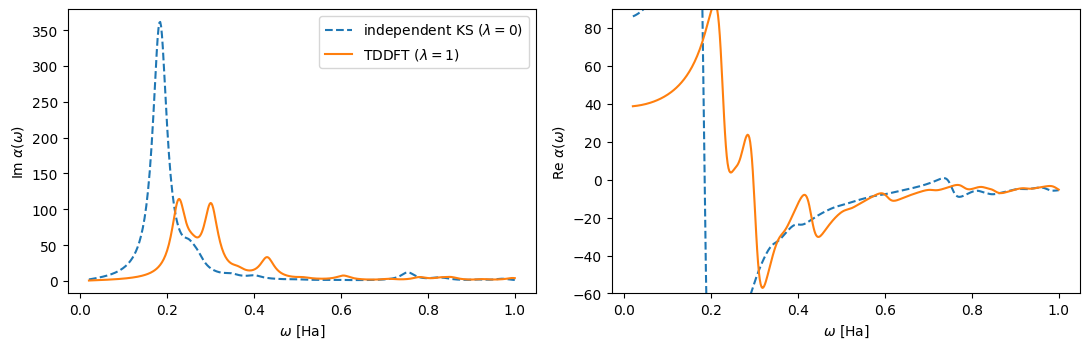

In [12]:
ws = np.linspace(0.02, 1.0, 491); g_s = 0.02
t0 = time.time()
spec = {lam: np.array([alpha_linear(mol, w, g_s, 'cgne', lam=lam, tol=1e-10)[0] for w in ws]) for lam in (0.0, 1.0)}
print(f"{2*len(ws)} frequency-points solved in {time.time()-t0:.1f} s")
def peaks(a):
    im = a.imag; return [ws[i] for i in range(1, len(ws)-1) if im[i] > im[i-1] and im[i] > im[i+1] and im[i] > 0.05*im.max()]
print("KS-only peaks   :", np.round(peaks(spec[0.0]), 3))
print("TDDFT peaks     :", np.round(peaks(spec[1.0]), 3))
print("static polarizability  KS: %.1f   TDDFT: %.1f" % (spec[0.0][0].real, spec[1.0][0].real))
trans = sorted(mol.eps[a]-mol.eps[i] for i in range(mol.no) for a in range(mol.no, mol.M))[:6]
print("lowest KS transition energies:", np.round(trans, 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(ws, spec[0.0].imag, '--', label='independent KS ($\\lambda=0$)'); ax[0].plot(ws, spec[1.0].imag, label='TDDFT ($\\lambda=1$)')
ax[0].set_xlabel('$\\omega$ [Ha]'); ax[0].set_ylabel('Im $\\alpha(\\omega)$'); ax[0].legend()
ax[1].plot(ws, spec[0.0].real, '--'); ax[1].plot(ws, spec[1.0].real)
ax[1].set_xlabel('$\\omega$ [Ha]'); ax[1].set_ylabel('Re $\\alpha(\\omega)$'); ax[1].set_ylim(-60, 90)
plt.tight_layout(); plt.show()

### Test 4 — Does the Sylvester preconditioner help?
Counting CGNE iterations to a relative residual of $10^{-12}$ for the linear tier at several frequencies, with and without the element-wise preconditioner.

In [13]:
print("   w     iterations (preconditioned)   iterations (no preconditioner)")
for w in (0.05, 0.15, 0.25, 0.4, 0.6, 0.9):
    _, it1, _ = alpha_linear(mol, w, gamma, 'cgne', tol=1e-12)
    _, it0, _ = alpha_linear(mol, w, gamma, 'cgne', tol=1e-12, precond=False)
    print(f"{w:5.2f}   {it1:14d}                 {it0:14d}")

   w     iterations (preconditioned)   iterations (no preconditioner)
 0.05               13                            429
 0.15               15                            448
 0.25               17                            465
 0.40               18                            471
 0.60               19                            477
 0.90               21                            568


Unlike in the HEOM toy model of the previous tutorial, the preconditioner is a **large** win here (a factor of about $25$–$33$): the Kohn–Sham energy differences span a wide range, so the unpreconditioned operator is badly scaled, and dividing by $\Omega+i\gamma-(\varepsilon_p-\varepsilon_q)$ removes exactly that.

### Test 5 — The nonlinear steady state against real-time propagation, and the harmonic hierarchy
A stronger field, $E_0=0.02$ at $\omega=0.4$. We solve the harmonic hierarchy with Newton–Krylov for several cutoffs $H$ and compare the dipole harmonics $\mu_n=-2\,\mathrm{Tr}(x\Delta_n)$ with the real-time result. $\mu_0$ is the **rectified** (dc) dipole, an effect of even order that exists only because the molecule is asymmetric.

In [14]:
w, E0 = 0.4, 0.02
ref, _ = rtp(mol, w, E0, gamma, dt=0.05, nper_fit=4)
print("real-time reference  mu_n:", [complex(np.round(ref[n], 6)) for n in range(4)])
print("\n  H   rel.error mu_0  mu_1     mu_2     mu_3     time   CGNE iterations")
for H in (1, 2, 3, 4, 5):
    fl = Floquet(mol, w, E0, gamma, H=H)
    t0 = time.time(); fl.solve_newton(tol=1e-7); dt = time.time() - t0
    e = [abs(fl.dipole(n) - ref[n])/abs(ref[n]) if n <= H else np.nan for n in range(4)]
    print(f"  {H}   " + "  ".join(f"{x:8.1e}" for x in e) + f"   {dt:4.1f}s  {fl.inner:7d}")

real-time reference  mu_n: [(0.028436+0j), (-0.151989+0.21132j), (0.002364+0.000666j), (0.00013-7.1e-05j)]

  H   rel.error mu_0  mu_1     mu_2     mu_3     time   CGNE iterations
  1    5.1e-01   9.0e-02       nan       nan    1.8s     3184
  2    1.9e-03   5.5e-03   6.5e-02       nan   12.2s     4674
  3    5.2e-04   1.5e-04   1.3e-03   2.9e-01   13.0s     5761
  4    5.5e-06   2.5e-06   5.6e-05   2.3e-02   13.9s     7150
  5    1.5e-05   9.6e-07   4.5e-05   2.4e-04   15.3s     8612


The error falls geometrically with the harmonic cutoff $H$ — the exact analogue of converging a HEOM calculation in the hierarchy depth $N_T$ — and by $H=4$ the steady state agrees with the real-time result to $6\times10^{-5}$ or better for $\mu_0,\mu_1,\mu_2$ (the third harmonic needs $H=5$, where it agrees to $2\times10^{-4}$). Beyond $H=4$ the remaining differences, at the $10^{-5}$ level, are those of the real-time reference itself.

### Test 6 — Perturbation theory as a check: $\mu_n\propto E_0^n$
In the weak-field regime the $n$-th harmonic must scale as $E_0^{\,n}$ (and the dc term as $E_0^2$). The log-slopes between successive field strengths should approach $2,1,2,3$ for $\mu_0,\dots,\mu_3$.

In [ ]:
prev = None
print("   E0        |mu_0|       |mu_1|       |mu_2|       |mu_3|      log2-slopes")
for E0 in (0.0025, 0.005, 0.01, 0.02):
    fl = Floquet(mol, 0.4, E0, gamma, H=4); fl.solve_newton(tol=1e-8)
    m = [abs(fl.dipole(n)) for n in range(4)]
    print(f"{E0:7.4f}   " + "  ".join(f"{x:10.3e}" for x in m) + ("" if prev is None else "   " + str([round(np.log2(a/b), 2) for a, b in zip(m, prev)])))
    prev = m

   E0        |mu_0|       |mu_1|       |mu_2|       |mu_3|      log2-slopes
 0.0025    4.445e-04   3.325e-02   3.073e-05   2.603e-07
 0.0050    1.783e-03   6.644e-02   1.241e-04   2.087e-06   [np.float64(2.0), np.float64(1.0), np.float64(2.01), np.float64(3.0)]
 0.0100    7.168e-03   1.324e-01   5.178e-04   1.694e-05   [np.float64(2.01), np.float64(0.99), np.float64(2.06), np.float64(3.02)]


### Test 7 — The electronic structure in the field: induced density
The steady state is a full density matrix, so we can look at how the *electron density itself* is driven. At the lowest TDDFT resonance the first harmonic $\Delta n_1(x)$ shows the dipolar oscillation of the electron cloud; $\Delta n_0(x)$ is the time-averaged (rectified) change and $\Delta n_2(x)$ the second-harmonic density.

In [ ]:
w_res = peaks(spec[1.0])[0]; E0 = 0.01
fl = Floquet(mol, w_res, E0, gamma, H=4); fl.solve_newton(tol=1e-7)
x = mol.x
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4), sharex=True)
d1, d0, d2 = mol.dens(fl.Dh[1]), mol.dens(fl.Dh[0]).real, mol.dens(fl.Dh[2])
ax[0].plot(x, d1.real, label='Re'); ax[0].plot(x, d1.imag, '--', label='Im'); ax[0].set_title(f'$\\Delta n_1(x)$ at $\\omega={w_res:.3f}$'); ax[0].legend()
ax[1].plot(x, d0); ax[1].set_title('$\\Delta n_0(x)$ (time-averaged)')
ax[2].plot(x, d2.real, label='Re'); ax[2].plot(x, d2.imag, '--', label='Im'); ax[2].set_title('$\\Delta n_2(x)$ (second harmonic)')
for a in ax: a.set_xlabel('x [bohr]'); a.set_xlim(-8, 8)
plt.tight_layout(); plt.show()
print("dipole harmonics mu_0, mu_1, mu_2:", [complex(np.round(fl.dipole(n), 6)) for n in range(3)])
print("particle number conserved by every harmonic (integral of Delta n_n):", [float(abs(np.sum(mol.dens(fl.Dh[n]))*mol.dx)) for n in range(3)])

### Test 8 — Why the iterative route matters: scaling with system size
We grow the molecule to a chain of alternating $Z=3,1$ nuclei and compare, for one linear tier, the **dense** solve of the explicit $(2n_vn_o)^2$ matrix with matrix-free **CGNE**. The dense memory is the size of the matrix; the CGNE working storage is a handful of copies of $X,Y$ plus the orbitals and the kernel (estimated, not measured).

In [ ]:
w_s, g_s = 0.3, 0.05
print("   k  n_occ    M  n_virt   unknowns | dense: time[s] memory[MB] | CGNE: iters time[s] memory[MB] | |d alpha|")
for k in (1, 2, 3, 4, 5):
    pos = [3.0*(j - (2*k-1)/2) for j in range(2*k)]; L = abs(pos[0]) + 13
    M = min(10 + 40*k, int(2*L/0.25))
    m = Molecule([3, 1]*k, pos, L=L, dx=0.25, M=M); n = m.nv*m.no
    t0 = time.time(); a_c, it, _ = alpha_linear(m, w_s, g_s, 'cgne', tol=1e-10); tc = time.time() - t0
    mem_c = (8*n*16 + m.Ng*m.M*8 + m.Ng*m.Ng*8)/1e6
    t0 = time.time(); a_d, _, _ = alpha_linear(m, w_s, g_s, 'dense'); td = time.time() - t0
    print(f"{k:4d} {m.no:6d} {m.M:5d} {m.nv:7d} {2*n:10d} | {td:10.2f} {(2*n)**2*16/1e6:10.1f} | {it:10d} {tc:8.3f} {mem_c:9.1f} | {abs(a_c-a_d):.1e}")

The dense memory grows as $(n_vn_o)^2$ and its solve time as $(n_vn_o)^3$; CGNE storage grows roughly linearly in $n_vn_o$, and its iteration count grows only slowly (16 to 44 over this range). In this 1D model the sizes stay small enough that the dense solve is still feasible; the same scaling is what matters for 3D molecules with hundreds of occupied–virtual pairs per orbital.

## 7. What to take away, and what not to
* The HEOM idea carries over: write the driven-dissipative steady state as **coupled matrix equations in the Kohn–Sham eigenbasis**, apply the operator and its adjoint matrix-free, and precondition with the **element-wise Sylvester division** — a factor of $25$–$33$ in iterations here.
* The Floquet **harmonic cutoff** $H$ is the analogue of the HEOM tier; the error drops geometrically with it.
* The nonlinear steady state needed a **Newton–Krylov outer loop**; plain Picard and Anderson iteration stalled at the stronger fields we tried.
* **Limits.** 1D soft-Coulomb model; exchange-only adiabatic LDA (no correlation, no memory); a truncated Kohn–Sham basis ($M=50$ orbitals, so no sum rules); damping is phenomenological (relaxation toward the ground-state density matrix); the real-time reference shares all these approximations, so the tests check the solver, not the physics. Convergence of the outer iteration is not guaranteed near strong resonances.

**Exercises.** (1) Add a fraction of exact exchange. (2) Replace dipole coupling by a vector potential. (3) Find the largest $E_0$ for which Newton–Krylov converges at the first resonance. (4) Let the damping be state-dependent. (5) Compare $\mu_2$ with a finite-field ground-state calculation.

**Reference.** C. Kaspar and M. Thoss, J. Phys. Chem. A **125**, 5190–5200 (2021), https://doi.org/10.1021/acs.jpca.1c02863